# 현실의 데이터 12: 강판 표면 결함 분류

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/notebooks/datashop/12_steel_defects.ipynb)

**분야**: 제조 &nbsp;|&nbsp; **이 분야에서 먼저 보는 문제**: 품질 검사 · 결함 종류 분류 · 검사 자동화

> 철강 판 1,941장, 결함 7종류. 결함 모양을 잰 숫자 27개로 어떤 결함인지 맞힐 수 있을까?

**데이터**: Steel Plates Faults (약 0.1MB). UCI, Semeion 연구소 (Buscema, Terzi & Tastle, 2010). 강판 결함 1,941개, 결함 영역의 위치 · 면적 · 둘레 · 밝기 · 강판 종류 · 두께 등 27개, 결함 7종류.

인턴 · 산학협력 과제에서 처음 받게 될 데이터와 닮은 공개 데이터다. 데이터를 열어 보고, 아래 예시처럼 문제 하나를 정해 기준선과 비교한 뒤, 맨 끝의 **나의 다섯 칸** 을 채운다 (1주 2차시 '문제 정형화와 평가지표').

| 칸 | 이 노트북의 예시 |
|---|---|
| ① 한 행 | 결함 하나 |
| ② 입력 X | 결함 영역의 크기 · 모양 · 밝기 · 강판 종류 · 두께 (27개) |
| ③ 출력 y | 결함 종류 7가지 |
| ④ 평가지표 | 정확도 + 종류별 재현율 |
| ⑤ 기준선 | 가장 흔한 종류 |

**논문 · 출처** (직접 열어 보자: 이 데이터를 누가, 왜, 어떻게 만들었나):
- [UCI Steel Plates Faults 데이터 설명 (Semeion Research Center)](https://archive.ics.uci.edu/dataset/198/steel+plates+faults)

In [1]:
import io, os, zipfile, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def download(url, path):
    """Download url to path once (skip if it already exists)"""
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    if not os.path.exists(path):
        req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (ML course data shop)"})
        with urllib.request.urlopen(req, timeout=600) as r, open(path, "wb") as f:
            f.write(r.read())
    return path

## 입장: 데이터 받기

숫자 표 (`Faults.NNA`) 와 열 이름 (`Faults27x7_var`) 이 따로 들어 있다. 마지막 7개 열이 결함 종류 (하나만 1).

In [2]:
URL = "https://archive.ics.uci.edu/static/public/198/steel+plates+faults.zip"
with zipfile.ZipFile(download(URL, "data/steel_faults.zip")) as z:
    names = z.read("Faults27x7_var").decode().split()
    df = pd.read_csv(z.open("Faults.NNA"), sep=r"\s+", header=None, names=names)
faults = names[-7:]
df["fault"] = df[faults].idxmax(axis=1)
print(df.shape)
print(df["fault"].value_counts())

(1941, 35)
fault
Other_Faults    673
Bumps           402
K_Scatch        391
Z_Scratch       190
Pastry          158
Stains           72
Dirtiness        55
Name: count, dtype: int64


## 열어 보기

결함 종류마다 크기 (`Pixels_Areas`) 와 밝기 (`Sum_of_Luminosity`) 가 다를까?

              Pixels_Areas  Steel_Plate_Thickness  Maximum_of_Luminosity
fault                                                                   
Bumps                120.0                   70.0                  127.0
Dirtiness            145.0                  100.0                  132.0
K_Scatch            6281.0                   40.0                  134.0
Other_Faults         146.0                   70.0                  127.0
Pastry               209.0                   85.0                  126.0
Stains                16.0                   50.0                  140.0
Z_Scratch            146.0                   70.0                  124.0


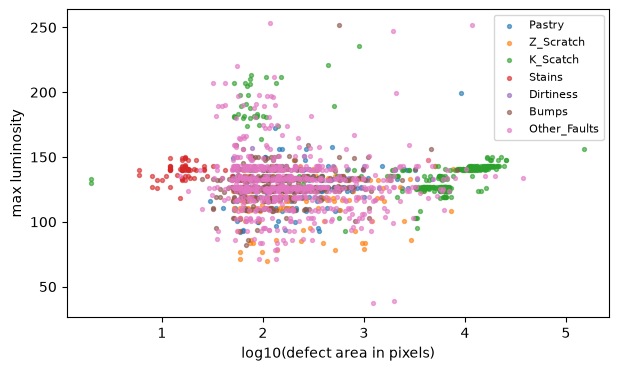

In [3]:
print(df.groupby("fault")[["Pixels_Areas", "Steel_Plate_Thickness", "Maximum_of_Luminosity"]].median().round(0))
plt.figure(figsize=(7, 4))
for f in df["fault"].unique():
    s = df[df["fault"] == f]
    plt.scatter(np.log10(s["Pixels_Areas"]), s["Maximum_of_Luminosity"], s=8, alpha=0.6, label=f)
plt.xlabel("log10(defect area in pixels)"); plt.ylabel("max luminosity"); plt.legend(fontsize=8); plt.show()

## 문제 하나 골라 보기: 결함 → 종류 (7가지 분류)

기준선 = 가장 흔한 종류. 모델 = 랜덤 포레스트 (7주차). 무엇을 많이 틀릴까?

In [4]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

X, y = df[names[:-7]], df["fault"]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=0)
most_common = ytr.value_counts().idxmax()
m = RandomForestClassifier(500, random_state=0).fit(Xtr, ytr)
pred = m.predict(Xte)
print(f"baseline (always '{most_common}'): accuracy {np.mean(yte == most_common):.1%}")
print(f"random forest                   : accuracy {np.mean(yte == pred):.1%}")
print("recall per fault:", pd.Series(yte.values == pred).groupby(yte.values).mean().round(2).to_dict())

baseline (always 'Other_Faults'): accuracy 34.6%
random forest                   : accuracy 80.3%
recall per fault: {'Bumps': 0.78, 'Dirtiness': 0.76, 'K_Scatch': 0.92, 'Other_Faults': 0.77, 'Pastry': 0.6, 'Stains': 0.95, 'Z_Scratch': 0.86}


**관찰**: 'Pastry' 가 가장 많이 틀린다. 'Other_Faults' (기타 결함) 는 가장 많지만, '기타' 라는 라벨은 사람이 분류하기 애매했던 것들의 모음이라 경계가 흐리다. 라벨을 어떻게 나눴는지도 문제 정의의 일부다.

## 다른 문제로 바꿔 보기

- **검사 자동화**: 현장에서는 이 27개 숫자가 아니라 **카메라 사진** 이 들어온다. 한 행 = 사진, y = 결함 위치 (상자) + 종류로 바꾸면? (10주차 CNN)
- '정상 강판' 이 이 데이터에는 없다. 결함 여부부터 가려야 한다면 어떤 데이터가 더 필요할까?
- 결함 종류마다 비용이 다르다면 (예: 긁힘은 재가공, 얼룩은 폐기) 지표를 어떻게 바꿀까?

### 나의 다섯 칸

아래 표를 직접 채워 보자. 위의 예시와 다르게 정해도 된다.

| 칸 | 내가 정한 것 |
|---|---|
| ① 한 행은 무엇? | |
| ② 입력 X (예측할 때 알 수 있는 것만) | |
| ③ 출력 y | |
| ④ 평가지표 | |
| ⑤ 기준선 | |